**TOPIK 2 – Kebiasaan Penggunaan Teknologi**



**Langkah 1 – Persiapan lingkungan dan impor pustaka**

In [1]:
import re
import pandas as pd
import numpy as np
from scipy import stats
from google.colab import files

**Langkah 2 – Unggah berkas data**

In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx to Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx
File terbaca: Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx


**Langkah 3 – Membaca data dan memisahkan butir**

In [3]:
JUMLAH_KOLOM_DEMOGRAFI = 6          # ubah sesuai jumlah kolom demografi pada data

df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 30
Jumlah butir     : 29
Data kosong      : 0


**Langkah 4 – Mengubah jawaban Likert menjadi angka**

In [4]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_42483/3609573047.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI hampir setiap kali mendapatkan tugas atau projek kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari penyelesaian soal atau permasalahan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi saat mengerjakan tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk memahami materi kuliah yang belum saya kuasai.],"Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk menyusun atau memperbaiki tulisan dalam tugas kuliah, misalnya laporan atau makalah.]",Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk membuat atau memperbaiki kode program pada tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan lebih dari satu platform AI untuk menyelesaikan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan menyelesaikan tugas kuliah tanpa bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung langsung mengikuti jawaban AI tanpa mempertimbangkan sumber lain.],...,Kebiasaan penggunaan teknologi digital [Konsentrasi saya mudah terganggu oleh gadget ketika sedang mengerjakan tugas kuliah.],Prokrastinasi akademik [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik [Saya sering menunda tugas karena merasa tugas tersebut dapat diselesaikan dengan cepat menggunakan AI.],Prokrastinasi akademik [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik [Saya sering harus mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas dengan hasil tugas yang dikerjakan terburu-buru menjelang deadline.],Respon emosional [Saya merasa gelisah ketika mengingat tugas yang belum saya kerjakan.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,2,4,4,4,4,4,4,2,2,2,...,1,2,2,2,2,4,4,4,4,4
1,4,4,4,4,4,4,4,4,2,2,...,4,4,4,4,4,4,4,4,4,4
2,5,5,5,5,5,5,5,5,4,4,...,5,2,5,5,5,5,5,5,5,5
3,4,5,5,5,4,4,4,4,2,2,...,4,4,2,5,4,4,4,2,5,4
4,5,4,5,5,5,4,5,5,4,1,...,4,1,2,1,2,5,5,4,4,4


**Langkah 5 – Mengelompokkan butir per dimensi**

In [5]:
dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1)
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


**Langkah 5b – Memilih dimensi topik ini**

In [6]:
TOPIK = [
    "Kebiasaan penggunaan teknologi digital",
    "Prokrastinasi akademik",
    "Respon emosional",
]

dimensi = {nama: dimensi[nama] for nama in TOPIK}

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


**Langkah 6 – Uji validitas (korelasi Pearson butir-total)**

In [7]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 30 | r tabel (α=0,05; df=28) = 0.361


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Kebiasaan penggunaan teknologi digital,B1,0.804,0.712,0.0,Valid
1,Kebiasaan penggunaan teknologi digital,B2,0.701,0.577,0.0,Valid
2,Kebiasaan penggunaan teknologi digital,B3,0.881,0.814,0.0,Valid
3,Kebiasaan penggunaan teknologi digital,B4,0.890,0.826,0.0,Valid
4,Kebiasaan penggunaan teknologi digital,B5,0.815,0.725,0.0,Valid
5,Kebiasaan penggunaan teknologi digital,B6,0.716,0.590,0.0,Valid
6,Prokrastinasi akademik,B1,0.849,0.726,0.0,Valid
7,Prokrastinasi akademik,B2,0.845,0.716,0.0,Valid
8,Prokrastinasi akademik,B3,0.803,0.629,0.0,Valid
9,Prokrastinasi akademik,B4,0.869,0.766,0.0,Valid


**Langkah 7 – Uji reliabilitas (Cronbach's alpha)**

In [8]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Kebiasaan penggunaan teknologi digital,6,0.890,Baik
1,Prokrastinasi akademik,4,0.860,Baik
2,Respon emosional,5,0.928,Sangat baik


,Dimensi,Butir,Alpha jika dihapus
0,Kebiasaan penggunaan teknologi digital,B1,0.870
1,Kebiasaan penggunaan teknologi digital,B2,0.890
2,Kebiasaan penggunaan teknologi digital,B3,0.852
3,Kebiasaan penggunaan teknologi digital,B4,0.850
4,Kebiasaan penggunaan teknologi digital,B5,0.868
5,Kebiasaan penggunaan teknologi digital,B6,0.888
6,Prokrastinasi akademik,B1,0.814
7,Prokrastinasi akademik,B2,0.818
8,Prokrastinasi akademik,B3,0.857
9,Prokrastinasi akademik,B4,0.799


**Langkah 8 – Menggabungkan dan mengunduh hasil**

In [9]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Langkah 9 – Analisis distribusi: statistik deskriptif, skewness, kurtosis, dan uji normalitas**

In [10]:
# Skor tiap responden per dimensi = rata-rata jawaban butir (skala 1–5)
skor = pd.DataFrame({nama: num[daftar].mean(axis=1) for nama, daftar in dimensi.items()})

hasil_distribusi = []
for nama in skor.columns:
    s = skor[nama]
    p_normal = stats.shapiro(s).pvalue
    hasil_distribusi.append({
        "Dimensi": nama,
        "n": len(s),
        "Mean": round(s.mean(), 3),
        "Median": round(s.median(), 3),
        "Modus": round(s.mode().iloc[0], 3),
        "SD": round(s.std(), 3),
        "Min": round(s.min(), 3),
        "Max": round(s.max(), 3),
        "Skewness": round(stats.skew(s, bias=False), 3),
        "Kurtosis": round(stats.kurtosis(s, bias=False), 3),
        "Shapiro-Wilk p": round(p_normal, 4),
        "Distribusi": "Normal" if p_normal > 0.05 else "Tidak normal",
    })

tabel_distribusi = pd.DataFrame(hasil_distribusi)
tabel_distribusi

,Dimensi,n,Mean,Median,Modus,SD,Min,Max,Skewness,Kurtosis,Shapiro-Wilk p,Distribusi
0,Kebiasaan penggunaan teknologi digital,30,3.589,3.917,5.0,1.239,1.167,5.0,-0.487,-1.015,0.0111,Tidak normal
1,Prokrastinasi akademik,30,3.042,3.000,1.5,1.377,1.000,5.0,-0.078,-1.453,0.0206,Tidak normal
2,Respon emosional,30,4.140,4.500,5.0,1.159,1.000,5.0,-2.083,3.646,0.0000,Tidak normal


**Langkah 10 – Distribusi frekuensi jawaban per dimensi (%)**

In [11]:
label = ["STS", "TS", "N", "S", "SS"]
frekuensi = {}
for nama, daftar in dimensi.items():
    v = num[daftar].stack().value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    frekuensi[nama] = (v / v.sum() * 100).round(1).values

tabel_frekuensi = pd.DataFrame(frekuensi, index=label).T
tabel_frekuensi

,STS,TS,N,S,SS
Kebiasaan penggunaan teknologi digital,15.6,17.8,0.0,25.6,41.1
Prokrastinasi akademik,25.0,25.0,0.8,19.2,30.0
Respon emosional,11.3,3.3,0.0,30.7,54.7


**Langkah 11 – Histogram distribusi skor per dimensi**

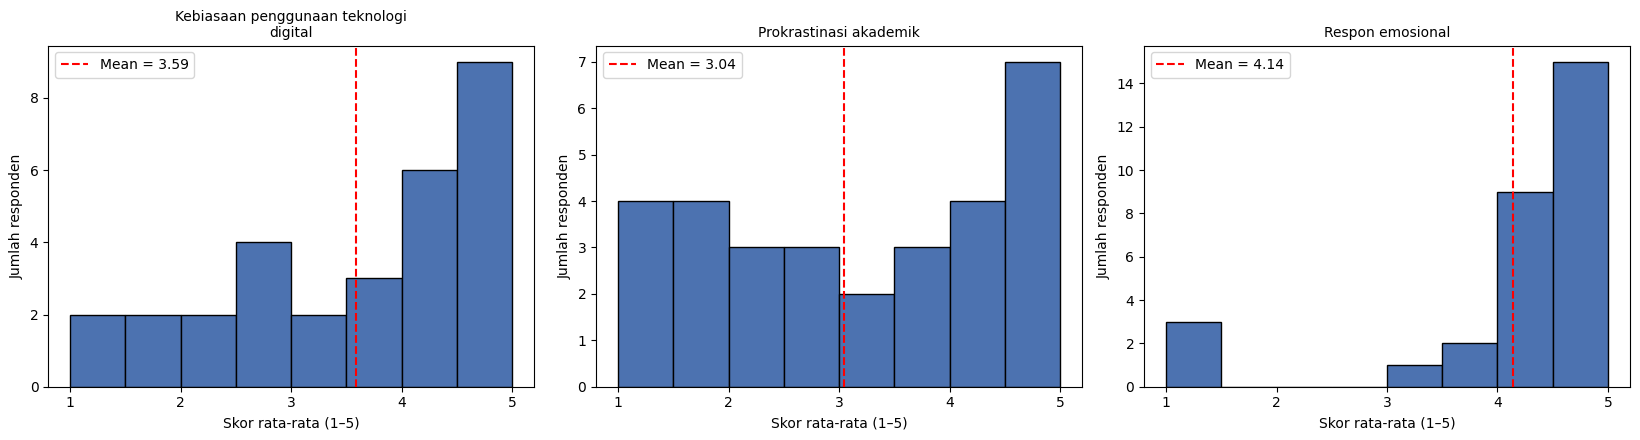

In [12]:
import matplotlib.pyplot as plt
import textwrap

fig, axes = plt.subplots(1, len(skor.columns), figsize=(5.5 * len(skor.columns), 4.5))
for ax, nama in zip(np.atleast_1d(axes), skor.columns):
    ax.hist(skor[nama], bins=np.arange(1, 5.5, 0.5), edgecolor="black", color="#4C72B0")
    ax.axvline(skor[nama].mean(), color="red", linestyle="--", label=f"Mean = {skor[nama].mean():.2f}")
    ax.set_title("\n".join(textwrap.wrap(nama, 35)), fontsize=10)
    ax.set_xlabel("Skor rata-rata (1–5)")
    ax.set_ylabel("Jumlah responden")
    ax.set_xticks(range(1, 6))
    ax.legend()

plt.tight_layout()
plt.savefig("histogram_distribusi.png", dpi=150)
plt.show()